<a href="https://colab.research.google.com/github/artcoding93/Numerical-Recipe-Archive/blob/main/03_newton_raphson/newton_raphson_method.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

초기 예측값 V_0 = 0.6000 V
----------------------------------------
[1회 반복] V_D = 0.5849077 V (오차: 1.51e-02)
[2회 반복] V_D = 0.5784271 V (오차: 6.48e-03)
[3회 반복] V_D = 0.5774772 V (오차: 9.50e-04)
[4회 반복] V_D = 0.5774595 V (오차: 1.77e-05)
[5회 반복] V_D = 0.5774595 V (오차: 5.98e-09)


/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 54644 (\N{HANGUL SYLLABLE HAE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 51312 (\N{HANGUL SYLLABLE JO}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 44148 (\N{HANGUL SYLLABLE GEON}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


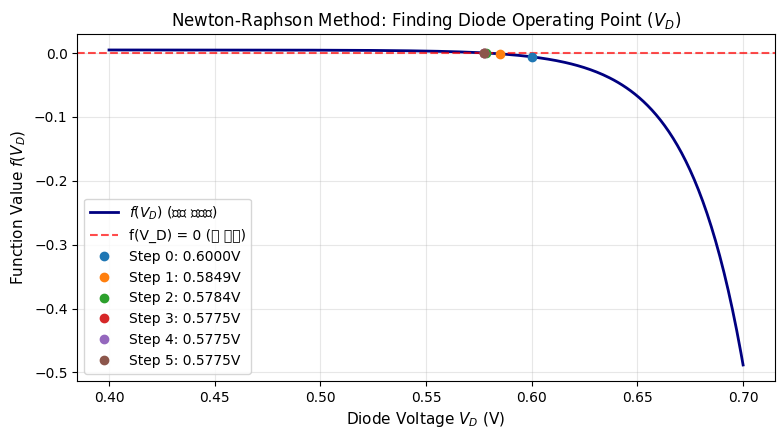

In [2]:
import numpy as np
import matplotlib.pyplot as plt

# 1. 회로 방정식 f(V_D) 정의
def f(v):
    return (5.0 - v) / 1000.0 - 1e-12 * (np.exp(v / 0.026) - 1.0)

# 2. 회로 방정식의 1차 도함수 f'(V_D) 정의
def df(v):
    return -1.0 / 1000.0 - (1e-12 / 0.026) * np.exp(v / 0.026)

# 3. 뉴턴-랩슨 알고리즘 실행
def newton_raphson(v0, tol=1e-7, max_iter=50):
    v = v0
    history = [v]
    print(f"초기 예측값 V_0 = {v:.4f} V\n" + "-"*40)

    for step in range(max_iter):
        f_val = f(v)
        df_val = df(v)

        # 뉴턴-랩슨 점화식 적용
        v_next = v - f_val / df_val
        diff = abs(v_next - v)
        history.append(v_next)

        print(f"[{step+1}회 반복] V_D = {v_next:.7f} V (오차: {diff:.2e})")

        if diff < tol:
            return v_next, history
        v = v_next

    return v, history

# 다이오드 턴온 전압 근처인 0.6V를 초깃값으로 설정하여 해 탐색
v_sol, history = newton_raphson(v0=0.6)

# ---------------------------------------------------------
# 4. f(x) 함수 그래프 및 수렴 과정 시각화
# ---------------------------------------------------------
v_vals = np.linspace(0.4, 0.7, 300)
f_vals = f(v_vals)

plt.figure(figsize=(9, 4.5))
plt.plot(v_vals, f_vals, label=r'$f(V_D)$ (회로 방정식)', color='navy', lw=2)
plt.axhline(0, color='red', linestyle='--', alpha=0.7, label='f(V_D) = 0 (해 조건)')

# 뉴턴-랩슨 탐색 과정 점 표시
for idx, v_step in enumerate(history):
    plt.plot(v_step, f(v_step), 'o', markersize=6, label=f'Step {idx}: {v_step:.4f}V')

plt.title('Newton-Raphson Method: Finding Diode Operating Point ($V_D$)', fontsize=12)
plt.xlabel('Diode Voltage $V_D$ (V)', fontsize=11)
plt.ylabel('Function Value $f(V_D)$', fontsize=11)
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()